In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer



In [2]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cwd = Path.cwd()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project Root:", PROJECT_ROOT)

Project Root: c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification


In [3]:
from src.data_loader import load_data

print("Data loader imported successfully!")

Data loader imported successfully!


In [4]:
DATA_PATH = PROJECT_ROOT / "data" / "twitter_disaster.xlsx"

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Dataset path: c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\data\twitter_disaster.xlsx
Dataset exists: True


In [5]:
df = load_data(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7613, 5)


In [6]:
df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [7]:
# Part 1
# Task 1.1 — Data Exploration
# Step 1 — Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 7613
Number of columns: 5


In [8]:
# Step 2 — Check column names
print("Columns in the dataset:")

for column in df.columns:
    print("-", column)

Columns in the dataset:
- id
- keyword
- location
- text
- target


In [9]:
# Step 3 — Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   str   
 2   location  5079 non-null   object
 3   text      7613 non-null   str   
 4   target    7613 non-null   int64 
dtypes: int64(2), object(1), str(2)
memory usage: 1.1+ MB


In [10]:
df.describe(include="all")

,id,keyword,location,text,target
count,7613.000000,7552,5079,7613,7613.00000
unique,NaN,221,3293,7503,NaN
top,NaN,fatalities,USA,11-Year-Old Boy Charged With Manslaughter of T...,NaN
freq,NaN,45,105,10,NaN
mean,5441.934848,NaN,NaN,NaN,0.42966
std,3137.116090,NaN,NaN,NaN,0.49506
min,1.000000,NaN,NaN,NaN,0.00000
25%,2734.000000,NaN,NaN,NaN,0.00000
50%,5408.000000,NaN,NaN,NaN,0.00000
75%,8146.000000,NaN,NaN,NaN,1.00000


In [11]:
# Step 4 — Missing-value analysis
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage.round(2)
})

missing_summary

,Missing Values,Percentage
id,0,0.00
keyword,61,0.80
location,2534,33.29
text,0,0.00
target,0,0.00


In [12]:
# Step 5 — Duplicate analysis
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate tweet texts:",
    df["text"].duplicated().sum()
)

Duplicate rows: 0
Duplicate tweet texts: 110


In [13]:
# Step 6 — Target distribution
target_counts = (
    df["target"]
    .value_counts()
    .sort_index()
)

target_counts

target
0    4342
1    3271
Name: count, dtype: int64

In [14]:
# Now percentages:
target_percentages = (
    df["target"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

target_percentages.round(2)

target
0    57.03
1    42.97
Name: proportion, dtype: float64

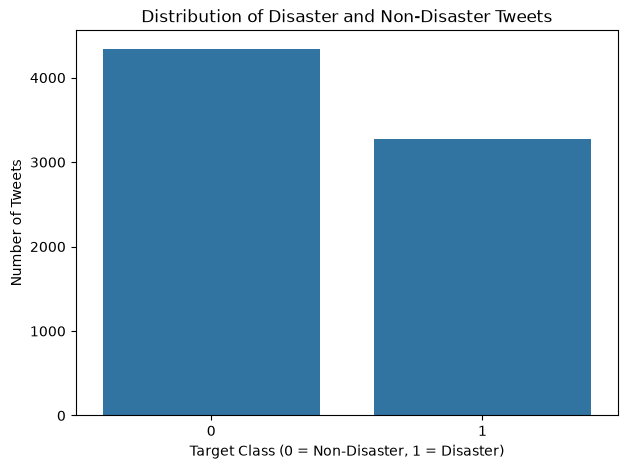

In [16]:
# Step 7 — Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="target"
)

plt.title("Distribution of Disaster and Non-Disaster Tweets")
plt.xlabel("Target Class (0 = Non-Disaster, 1 = Disaster)")
plt.ylabel("Number of Tweets")

plt.show()

### Insights
# - Non-Disaster tweets (Class 0): 4,342 (57.03%).
# - Disaster tweets (Class 1): 3,271 (42.97%).
# - The dataset has a moderate class imbalance, with more Non-Disaster tweets.
# - Both classes have enough samples for effective binary classification.
# - Stratified splitting and Stratified K-Fold cross-validation help maintain the class proportions during training and validation.

In [17]:
# Step 8 — Tweet-length analysis
df["tweet_length"] = (
    df["text"]
    .astype(str)
    .apply(len)
)

In [18]:
df[
    [
        "text",
        "tweet_length",
        "target"
    ]
].head()

,text,tweet_length,target
0,Our Deeds are the Reason of this #earthquake M...,69,1
1,Forest fire near La Ronge Sask. Canada,38,1
2,All residents asked to 'shelter in place' are ...,133,1
3,"13,000 people receive #wildfires evacuation or...",65,1
4,Just got sent this photo from Ruby #Alaska as ...,87,1


In [19]:
# compare two classes
df.groupby(
    "target"
)["tweet_length"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,4342.0,96.296868,36.450186,7.0,68.0,101.0,130.0,190.0
1,3271.0,108.828493,29.895684,14.0,88.0,115.0,136.0,176.0


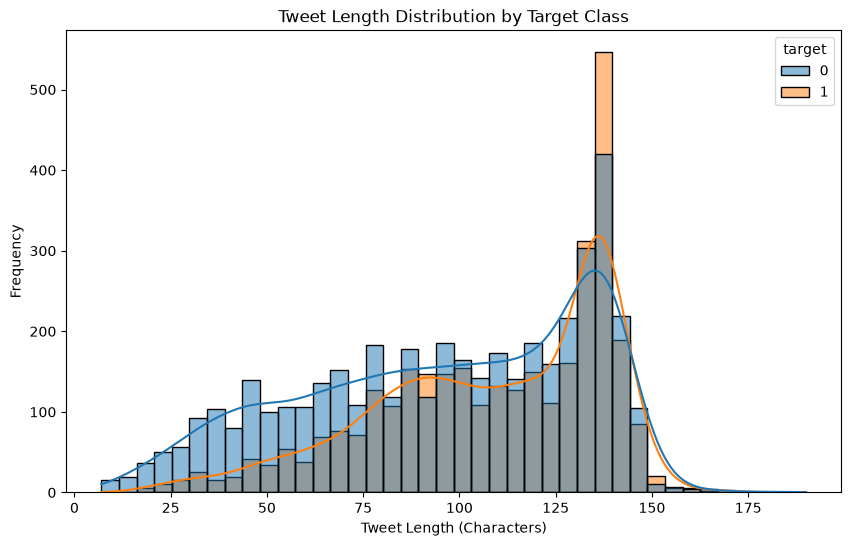

In [20]:
# Step 9 — Plot tweet lengths
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="tweet_length",
    hue="target",
    bins=40,
    kde=True
)

plt.title("Tweet Length Distribution by Target Class")
plt.xlabel("Tweet Length (Characters)")
plt.ylabel("Frequency")

plt.show()

### Insights – Tweet Length Distribution
# - Disaster tweets (Class 1) are generally concentrated at longer tweet lengths, especially around 125–145 characters.
# - Non-Disaster tweets (Class 0) are distributed across a wider range of lengths, including many shorter tweets.
# - Both classes show a strong concentration near 130–140 characters.
# - There is considerable overlap between the two distributions, so tweet length alone cannot reliably distinguish the classes.
# - Therefore, textual features such as TF-IDF are more important, while tweet length can serve as an additional supporting feature.

In [21]:
# Step 10 — Keyword analysis
print(
    "Number of unique keywords:",
    df["keyword"].nunique()
)

Number of unique keywords: 221


In [22]:
# Then find the 20 most common:
top_keywords = (
    df["keyword"]
    .dropna()
    .value_counts()
    .head(20)
)

top_keywords

keyword
fatalities     45
armageddon     42
deluge         42
body%20bags    41
damage         41
harm           41
sinking        41
collided       40
evacuate       40
fear           40
outbreak       40
siren          40
twister        40
windstorm      40
collision      39
derailment     39
earthquake     39
explosion      39
famine         39
flames         39
Name: count, dtype: int64

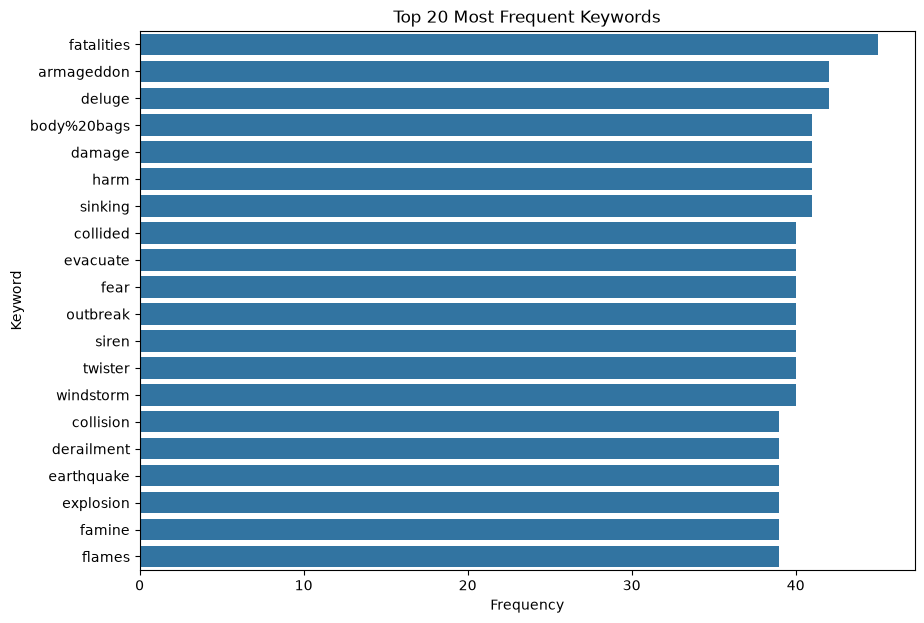

In [23]:
# Visualize:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_keywords.values,
    y=top_keywords.index
)

plt.title("Top 20 Most Frequent Keywords")
plt.xlabel("Frequency")
plt.ylabel("Keyword")

plt.show()

### Insights – Top 20 Most Frequent Keywords
# - “fatalities” is the most frequent keyword, appearing about 45 times.
# - Keywords such as “armageddon,” “deluge,” “damage,” “harm,” and “sinking” also occur frequently.
# - Most top keywords are strongly associated with disasters, accidents, destruction, or emergencies.
# - The frequencies of most top keywords are quite similar, generally around 39–42 occurrences.
# - Keywords such as “earthquake,” “explosion,” “famine,” “collision,” and “flames” can provide useful signals for disaster classification.
# - However, a disaster-related keyword does not always indicate a real disaster, so the model must consider the overall context of the tweet, not just individual keywords.

In [24]:
# Word-Frequency Analysis:
# Step 11 — Import Counter:
from collections import Counter
import re

In [25]:
# Step 12 — Separate disaster and non-disaster tweets:
disaster_text = " ".join(
    df.loc[df["target"] == 1, "text"].astype(str)
).lower()

non_disaster_text = " ".join(
    df.loc[df["target"] == 0, "text"].astype(str)
).lower()

In [26]:
# Step 13 — Extract words:
disaster_words = re.findall(
    r"\b[a-zA-Z]{3,}\b",
    disaster_text
)

non_disaster_words = re.findall(
    r"\b[a-zA-Z]{3,}\b",
    non_disaster_text
)

In [27]:
# Step 14 — Find the 20 most frequent words:
disaster_word_counts = Counter(disaster_words)
non_disaster_word_counts = Counter(non_disaster_words)

print("Top 20 words in Disaster Tweets:")
print(disaster_word_counts.most_common(20))

Top 20 words in Disaster Tweets:
[('http', 2382), ('the', 1361), ('and', 505), ('for', 401), ('from', 245), ('that', 209), ('with', 192), ('this', 182), ('after', 181), ('fire', 180), ('was', 169), ('are', 166), ('you', 142), ('have', 142), ('news', 140), ('amp', 135), ('https', 134), ('over', 128), ('more', 123), ('disaster', 121)]


In [28]:
print("Top 20 words in Non-Disaster Tweets:")
print(non_disaster_word_counts.most_common(20))

Top 20 words in Non-Disaster Tweets:
[('http', 1927), ('the', 1913), ('and', 919), ('you', 747), ('for', 491), ('that', 410), ('with', 380), ('this', 297), ('https', 277), ('like', 254), ('have', 242), ('are', 237), ('your', 231), ('just', 231), ('but', 226), ('was', 217), ('amp', 209), ('not', 204), ('out', 198), ('all', 193)]


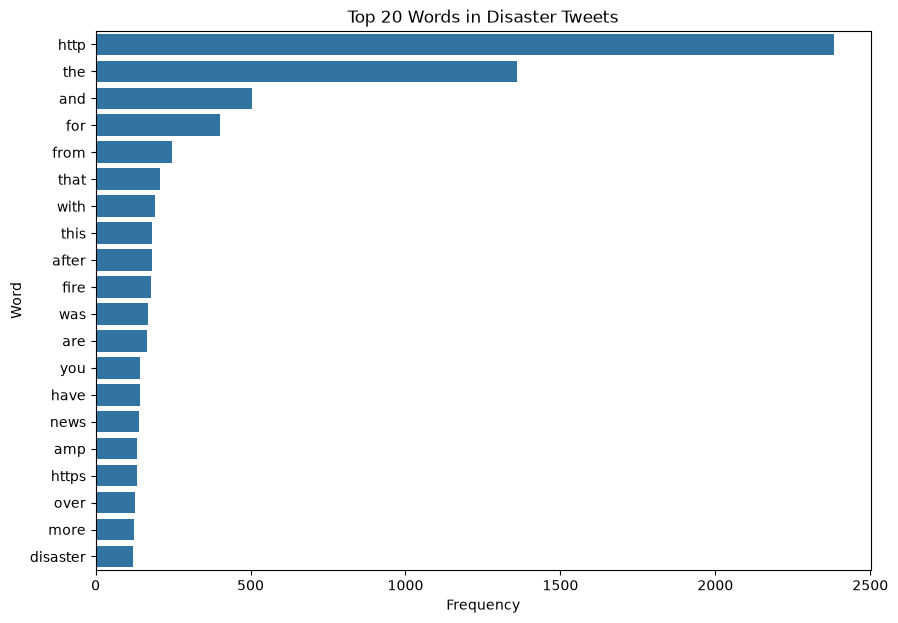

In [29]:
# Step 15 — Plot frequent disaster words:
top_disaster_words = pd.DataFrame(
    disaster_word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_disaster_words,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Words in Disaster Tweets")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

### Insights – Top 20 Words in Disaster Tweets
# - “http” is the most frequent term, showing that many disaster-related tweets contain links to external sources or news reports.
# - Common words such as “the,” “and,” “for,” and “from” appear frequently because this graph uses relatively raw tweet text.
# - Disaster-related words such as “fire,” “news,” and “disaster” are also among the frequent terms.
# - The presence of “http,” “https,” and “amp” indicates that raw tweets contain URLs and HTML/social-media noise.
# - This highlights the importance of text preprocessing and stopword removal before TF-IDF feature extraction and model training.
# - After cleaning, the model can focus more effectively on meaningful disaster-related words and phrases rather than common or noisy terms.

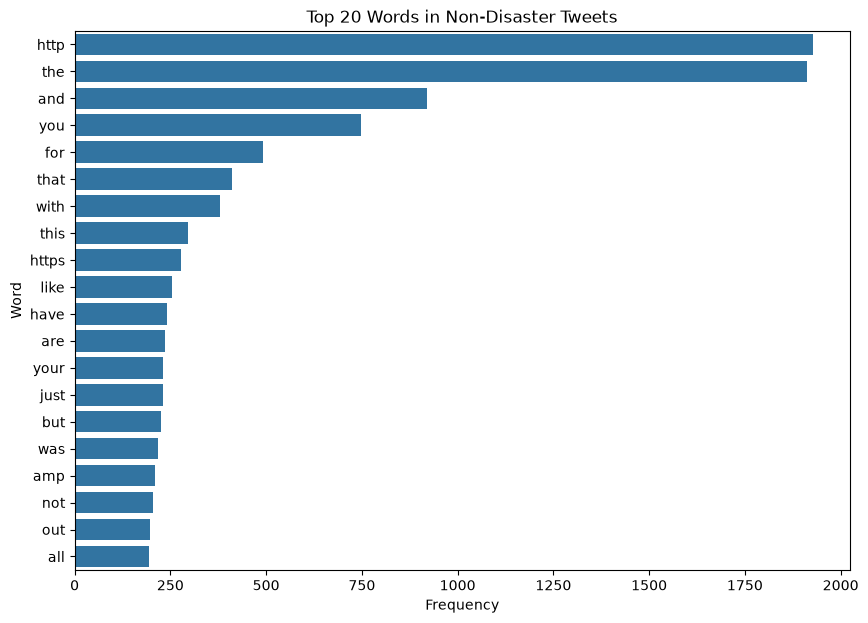

In [30]:
# Step 16 — Plot frequent non-disaster words:
top_non_disaster_words = pd.DataFrame(
    non_disaster_word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_non_disaster_words,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Words in Non-Disaster Tweets")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

### Insights – Top 20 Words in Non-Disaster Tweets
# - “http” and “the” are the most frequent words, appearing far more often than other terms.
# - Common conversational words such as “you,” “like,” “your,” “just,” and “not” occur frequently in Non-Disaster tweets.
# - “http,” “https,” and “amp” represent URLs or web/HTML-related noise rather than meaningful classification features.
# - Many stopwords such as “the,” “and,” “for,” “that,” and “with” dominate the raw text.
# - Compared with Disaster tweets, Non-Disaster tweets contain more general and conversational vocabulary.
# - This further supports the need for URL removal, text cleaning, stopword removal, and lemmatization before TF-IDF and model training.

## Task 1.2: Data Preparation

The raw tweet dataset is now prepared for machine learning.
Reusable preprocessing functions are implemented in `src/preprocessing.py`
to ensure that the same preprocessing pipeline can later be reused during
model training and deployment.

In [31]:
from src.preprocessing import handle_missing_values

In [32]:
df_prepared = handle_missing_values(df)

print("Shape before handling missing values:", df.shape)
print("Shape after handling missing values:", df_prepared.shape)

Shape before handling missing values: (7613, 6)
Shape after handling missing values: (7613, 6)


In [33]:
df_prepared.isnull().sum()

id              0
keyword         0
location        0
text            0
target          0
tweet_length    0
dtype: int64

In [34]:
# check how many values were replaced:
print(
    "Unknown keywords:",
    (df_prepared["keyword"] == "unknown").sum()
)

print(
    "Unknown locations:",
    (df_prepared["location"] == "unknown").sum()
)

Unknown keywords: 61
Unknown locations: 2534


In [35]:
# Step 2 — Handle duplicate tweets:
# 2.1 Check duplicate tweet texts:
duplicate_texts = df_prepared[
    df_prepared.duplicated(
        subset=["text"],
        keep=False
    )
].sort_values("text")

print(
    "Rows containing repeated tweet text:",
    len(duplicate_texts)
)

duplicate_texts[
    ["id", "text", "target"]
].head(20)

Rows containing repeated tweet text: 179


,id,text,target
4290,6094,#Allah describes piling up #wealth thinking it...,0
4299,6105,#Allah describes piling up #wealth thinking it...,0
4312,6123,#Allah describes piling up #wealth thinking it...,1
6363,9095,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6366,9098,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6373,9107,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6377,9113,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6378,9114,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
6392,9135,#Bestnaijamade: 16yr old PKK suicide bomber wh...,1
2822,4057,#KCA #VoteJKT48ID 12News: UPDATE: A family of ...,1


In [36]:
# 2.2 Check for conflicting labels:
conflicting_labels = (
    df_prepared
    .groupby("text")["target"]
    .nunique()
)

conflicting_labels = conflicting_labels[
    conflicting_labels > 1
]

print(
    "Tweet texts with conflicting target labels:",
    len(conflicting_labels)
)

Tweet texts with conflicting target labels: 18


In [37]:
if len(conflicting_labels) > 0:
    conflicting_tweets = df_prepared[
        df_prepared["text"].isin(
            conflicting_labels.index
        )
    ].sort_values("text")

    display(
        conflicting_tweets[
            ["id", "text", "target"]
        ]
    )
else:
    print("No conflicting duplicate tweets found.")

,id,text,target
4290,6094,#Allah describes piling up #wealth thinking it...,0
4299,6105,#Allah describes piling up #wealth thinking it...,0
4312,6123,#Allah describes piling up #wealth thinking it...,1
4221,5996,#foodscare #offers2go #NestleIndia slips into ...,1
4239,6023,#foodscare #offers2go #NestleIndia slips into ...,1
4244,6031,#foodscare #offers2go #NestleIndia slips into ...,0
2830,4068,.POTUS #StrategicPatience is a strategy for #G...,1
2831,4072,.POTUS #StrategicPatience is a strategy for #G...,1
2832,4076,.POTUS #StrategicPatience is a strategy for #G...,0
2833,4077,.POTUS #StrategicPatience is a strategy for #G...,1


In [38]:
# Step 3 — Add duplicate handling to preprocessing.py
from src.preprocessing import (
    handle_missing_values,
    remove_duplicates
)
print(
    "Before duplicate removal:",
    df_prepared.shape
)

df_prepared = remove_duplicates(
    df_prepared
)

print(
    "After duplicate removal:",
    df_prepared.shape
)

Before duplicate removal: (7613, 6)
After duplicate removal: (7613, 6)


In [39]:
%load_ext autoreload
%autoreload 2

In [41]:
from src.preprocessing import (
    handle_missing_values,
    remove_duplicates
)

print("Preprocessing functions imported successfully!")

Preprocessing functions imported successfully!


In [42]:
from pathlib import Path

preprocessing_file = (
    PROJECT_ROOT
    / "src"
    / "preprocessing.py"
)

print(preprocessing_file)

print("\n--- FILE CONTENT ---\n")

print(
    preprocessing_file.read_text(
        encoding="utf-8"
    )
)

c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\src\preprocessing.py

--- FILE CONTENT ---

import re
import pandas as pd


from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def handle_missing_values(df):
    """
    Handle missing values in the disaster tweet dataset.
    """

    df = df.copy()

    df["keyword"] = df["keyword"].fillna("unknown")
    df["location"] = df["location"].fillna("unknown")

    df = df.dropna(subset=["text"])
    df = df.dropna(subset=["target"])

    return df


def remove_duplicates(df):
    """
    Remove exact duplicate rows from the dataset.
    """

    df = df.copy()

    df = df.drop_duplicates()

    df = df.reset_index(drop=True)

    return df


def clean_text(text):
    """
    Clean raw tweet text for NLP processing.
    """

    # Convert to string and lowercase
    text = str(text).lower()

    # Replace HTML encoded ampersand
    text = text.replace("&amp

In [43]:
print(
    "Before duplicate removal:",
    df_prepared.shape
)

df_prepared = remove_duplicates(
    df_prepared
)

print(
    "After duplicate removal:",
    df_prepared.shape
)

print(
    "Exact duplicates remaining:",
    df_prepared.duplicated().sum()
)

Before duplicate removal: (7613, 6)
After duplicate removal: (7613, 6)
Exact duplicates remaining: 0


In [44]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [45]:
preprocessing_path = PROJECT_ROOT / "src" / "preprocessing.py"

print(preprocessing_path)

print("\nDoes clean_text exist in the file?")

file_content = preprocessing_path.read_text(
    encoding="utf-8"
)

print(
    "def clean_text" in file_content
)

c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\src\preprocessing.py

Does clean_text exist in the file?
True


In [46]:
import importlib
import src.preprocessing

importlib.reload(src.preprocessing)

print(
    [
        name
        for name in dir(src.preprocessing)
        if not name.startswith("_")
    ]
)

['WordNetLemmatizer', 'clean_text', 'handle_missing_values', 'pd', 'preprocess_data', 'preprocess_text', 're', 'remove_duplicates', 'stopwords']


In [47]:
from src.preprocessing import (
    handle_missing_values,
    remove_duplicates,
    clean_text
)

print("All preprocessing functions imported successfully!")

All preprocessing functions imported successfully!


In [48]:
sample_tweet = (
    "@BBCNews ALERT!! #Earthquake reported nearby 😨 "
    "Read more: https://example.com"
)

print("Original:")
print(sample_tweet)

print("\nCleaned:")
print(clean_text(sample_tweet))

Original:
@BBCNews ALERT!! #Earthquake reported nearby 😨 Read more: https://example.com

Cleaned:
alert earthquake reported nearby read more


In [49]:
df_prepared["clean_text"] = (
    df_prepared["text"]
    .apply(clean_text)
)

print("Text cleaning completed!")

Text cleaning completed!


In [50]:
df_prepared[
    ["text", "clean_text", "target"]
].head(10)

,text,clean_text,target
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...,1
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada,1
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...,1
3,"13,000 people receive #wildfires evacuation or...",people receive wildfires evacuation orders in ...,1
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...,1
5,#RockyFire Update => California Hwy. 20 closed...,rockyfire update california hwy closed in both...,1
6,#flood #disaster Heavy rain causes flash flood...,flood disaster heavy rain causes flash floodin...,1
7,I'm on top of the hill and I can see a fire in...,i m on top of the hill and i can see a fire in...,1
8,There's an emergency evacuation happening now ...,there s an emergency evacuation happening now ...,1
9,I'm afraid that the tornado is coming to our a...,i m afraid that the tornado is coming to our area,1


In [51]:
# Step 7 — Check for empty cleaned tweets
empty_tweets = (
    df_prepared["clean_text"]
    .str.strip()
    .eq("")
    .sum()
)

print(
    "Empty tweets after cleaning:",
    empty_tweets
)

Empty tweets after cleaning: 0


In [52]:
# Step 8 — Check cleaning examples
pd.set_option(
    "display.max_colwidth",
    None
)

df_prepared[
    ["text", "clean_text"]
].sample(10)

,text,clean_text
1975,[Tropical Cyclone Info] SOUDELOR 945hPa maximum wind speed: 45m/s maximum wind gust speed: 60m/s http://t.co/nBD5oT9iEW,tropical cyclone info soudelor hpa maximum wind speed m s maximum wind gust speed m s
5133,@Willie_Am_I @JusttheBottle I would cry in to my nuclear reactor cooling tank! #winechat,i would cry in to my nuclear reactor cooling tank winechat
5475,Aannnnd - 'Reddit Will Now Quarantine Offensive Content' https://t.co/P1JluRGWBu,aannnnd reddit will now quarantine offensive content
3299,Pls can alllll the nittys evacuate stockwell,pls can alllll the nittys evacuate stockwell
6364,Pic of 16yr old PKK suicide bomber who detonated bomb in Turkey Army trench released http://t.co/1yB8SiZarG http://t.co/69iIzvyQYC,pic of yr old pkk suicide bomber who detonated bomb in turkey army trench released
7197,Rare insight into #terror and How to fight it http://t.co/t6OBVWaPhW #Cameroon #USA #Whitehouse #ES #FR #Nigeria #UK #Africa #DE #CA #AU #JP,rare insight into terror and how to fight it cameroon usa whitehouse es fr nigeria uk africa de ca au jp
353,Build your own kingdom and lead your army to victory! https://youtu.\n\nStart g this friend code: LZKTJNOX http://t.co/zZ0cEwEw64,build your own kingdom and lead your army to victory start g this friend code lzktjnox
6804,I'm gunning down romance\nIt never did a thing for me\nBut heartache and misery\nAin't nothing but a tragedy http://t.co/jhUPOgbvs8,i m gunning down romance it never did a thing for me but heartache and misery ain t nothing but a tragedy
1070,New Documents Found Pointing To Japan's WWII Atomic Bomb Program http://t.co/IucPcSfbMT,new documents found pointing to japan s wwii atomic bomb program
4235,Caution: breathing may be hazardous to your health.,caution breathing may be hazardous to your health


In [53]:
import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\AMOGH\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\AMOGH\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\AMOGH\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [54]:
# Reload the module
import importlib
import src.preprocessing

importlib.reload(src.preprocessing)

<module 'src.preprocessing' from 'c:\\Users\\AMOGH\\Desktop\\Nexthikes_Projects\\Project_7_DisasterTweetClassification\\Disaster_Tweet_Classification\\src\\preprocessing.py'>

In [55]:
from src.preprocessing import (
    handle_missing_values,
    remove_duplicates,
    clean_text,
    preprocess_text
)

print("All preprocessing functions imported successfully!")

All preprocessing functions imported successfully!


In [56]:
# Test tokenization
sample_clean_text = (
    "earthquake reported nearby buildings damaged"
)

tokens = sample_clean_text.split()

print(tokens)

['earthquake', 'reported', 'nearby', 'buildings', 'damaged']


In [57]:
# See what stopword removal does
sample_text = (
    "the earthquake was reported in the city"
)

print("Before:")
print(sample_text)

print("\nAfter preprocessing:")
print(preprocess_text(sample_text))

Before:
the earthquake was reported in the city

After preprocessing:
earthquake reported city


In [58]:
# Test lemmatization
words = [
    "cars",
    "buildings",
    "fires",
    "storms"
]

lemmatizer = WordNetLemmatizer()

for word in words:
    print(
        word,
        "->",
        lemmatizer.lemmatize(word)
    )

cars -> car
buildings -> building
fires -> fire
storms -> storm


In [59]:
# Apply NLP preprocessing to the dataset
df_prepared["processed_text"] = (
    df_prepared["clean_text"]
    .apply(preprocess_text)
)

print("NLP preprocessing completed!")

NLP preprocessing completed!


In [60]:
# Now compare all three:
df_prepared[
    [
        "text",
        "clean_text",
        "processed_text",
        "target"
    ]
].head(10)

,text,clean_text,processed_text,target
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,our deeds are the reason of this earthquake may allah forgive us all,deed reason earthquake may allah forgive u,1
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada,forest fire near la ronge sask canada,1
2,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,all residents asked to shelter in place are being notified by officers no other evacuation or shelter in place orders are expected,resident asked shelter place notified officer evacuation shelter place order expected,1
3,"13,000 people receive #wildfires evacuation orders in California",people receive wildfires evacuation orders in california,people receive wildfire evacuation order california,1
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,just got sent this photo from ruby alaska as smoke from wildfires pours into a school,got sent photo ruby alaska smoke wildfire pours school,1
5,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,rockyfire update california hwy closed in both directions due to lake county fire cafire wildfires,rockyfire update california hwy closed direction due lake county fire cafire wildfire,1
6,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",flood disaster heavy rain causes flash flooding of streets in manitou colorado springs areas,flood disaster heavy rain cause flash flooding street manitou colorado spring area,1
7,I'm on top of the hill and I can see a fire in the woods...,i m on top of the hill and i can see a fire in the woods,top hill see fire wood,1
8,There's an emergency evacuation happening now in the building across the street,there s an emergency evacuation happening now in the building across the street,emergency evacuation happening building across street,1
9,I'm afraid that the tornado is coming to our area...,i m afraid that the tornado is coming to our area,afraid tornado coming area,1


In [61]:
# Check for empty processed tweets
empty_processed = (
    df_prepared["processed_text"]
    .str.strip()
    .eq("")
    .sum()
)

print(
    "Empty tweets after full preprocessing:",
    empty_processed
)

Empty tweets after full preprocessing: 2


In [62]:
# Compare random examples
pd.set_option(
    "display.max_colwidth",
    None
)

df_prepared[
    [
        "text",
        "clean_text",
        "processed_text"
    ]
].sample(10)

,text,clean_text,processed_text
402,#Kisii Police in Kisii hunt for students over failed arson plot: Police in Kisii hunt for students... http://t.co/5bdrFU1duo #CountyNews,kisii police in kisii hunt for students over failed arson plot police in kisii hunt for students countynews,kisii police kisii hunt student failed arson plot police kisii hunt student countynews
310,Red Faction: Armageddon (Microsoft Xbox 360 2011) - Full read by eBay http://t.co/ypbVS1IJya http://t.co/9dFLv6ynqr,red faction armageddon microsoft xbox full read by ebay,red faction armageddon microsoft xbox full read ebay
6060,Sinkhole Selfies: You Wont Believe What's In The Brooklyn Sinkhole! http://t.co/3gLYOyf6Oc,sinkhole selfies you wont believe what s in the brooklyn sinkhole,sinkhole selfies wont believe brooklyn sinkhole
2575,@SapphireScallop Destroy oppa image? Oops! There's nothing left right? Haaaaaa,destroy oppa image oops there s nothing left right haaaaaa,destroy oppa image oops nothing left right haaaaaa
5359,@brokenscnecal I just though about panic! at the disco when I said that,i just though about panic at the disco when i said that,though panic disco said
7024,Obama Declares Disaster for Typhoon-Devastated Saipan: Obama signs disaster declaration for Northern Marians a... http://t.co/qjuU0wcWPx,obama declares disaster for typhoon devastated saipan obama signs disaster declaration for northern marians a,obama declares disaster typhoon devastated saipan obama sign disaster declaration northern marians
2975,http://t.co/9y0pAJ8sxd Family mourns drowning of 'superhero' toddler with rare epilepsy - Chicago Tribune http://t.co/oLdjsowKY5,family mourns drowning of superhero toddler with rare epilepsy chicago tribune,family mourns drowning superhero toddler rare epilepsy chicago tribune
4808,matako_milk: Breaking news! Unconfirmed! I just heard a loud bang nearby. in what appears to be a blast of wind from my neighbour's ass.,matako milk breaking news unconfirmed i just heard a loud bang nearby in what appears to be a blast of wind from my neighbour s ass,matako milk breaking news unconfirmed heard loud bang nearby appears blast wind neighbour as
3662,@Jake_ADavis @FaTality_US we are cuddling right now so.. ??,we are cuddling right now so,cuddling right
2626,Megadeth-Symphony of Destruction http://t.co/xzfxRgLAlp,megadeth symphony of destruction,megadeth symphony destruction


In [63]:
import importlib
import src.preprocessing

importlib.reload(src.preprocessing)

from src.preprocessing import preprocess_data

print("Final preprocessing function imported successfully!")

Final preprocessing function imported successfully!


In [64]:
# complete preprocessing pipeline
df_prepared = preprocess_data(df)

print("Original dataset shape:", df.shape)
print("Prepared dataset shape:", df_prepared.shape)

Original dataset shape: (7613, 6)
Prepared dataset shape: (7611, 8)


In [65]:
# Check missing values
print("Missing values after preprocessing:")

df_prepared.isnull().sum()

Missing values after preprocessing:


id                0
keyword           0
location          0
text              0
target            0
tweet_length      0
clean_text        0
processed_text    0
dtype: int64

In [66]:
# Check duplicates
print(
    "Exact duplicate rows:",
    df_prepared.duplicated().sum()
)

Exact duplicate rows: 0


In [67]:
# Check empty processed tweets
empty_processed = (
    df_prepared["processed_text"]
    .str.strip()
    .eq("")
    .sum()
)

print(
    "Empty processed tweets:",
    empty_processed
)

Empty processed tweets: 0


In [68]:
# Inspect the result
pd.set_option(
    "display.max_colwidth",
    None
)

df_prepared[
    [
        "text",
        "clean_text",
        "processed_text",
        "target"
    ]
].head(10)

,text,clean_text,processed_text,target
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,our deeds are the reason of this earthquake may allah forgive us all,deed reason earthquake may allah forgive u,1
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada,forest fire near la ronge sask canada,1
2,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,all residents asked to shelter in place are being notified by officers no other evacuation or shelter in place orders are expected,resident asked shelter place notified officer evacuation shelter place order expected,1
3,"13,000 people receive #wildfires evacuation orders in California",people receive wildfires evacuation orders in california,people receive wildfire evacuation order california,1
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,just got sent this photo from ruby alaska as smoke from wildfires pours into a school,got sent photo ruby alaska smoke wildfire pours school,1
5,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,rockyfire update california hwy closed in both directions due to lake county fire cafire wildfires,rockyfire update california hwy closed direction due lake county fire cafire wildfire,1
6,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",flood disaster heavy rain causes flash flooding of streets in manitou colorado springs areas,flood disaster heavy rain cause flash flooding street manitou colorado spring area,1
7,I'm on top of the hill and I can see a fire in the woods...,i m on top of the hill and i can see a fire in the woods,top hill see fire wood,1
8,There's an emergency evacuation happening now in the building across the street,there s an emergency evacuation happening now in the building across the street,emergency evacuation happening building across street,1
9,I'm afraid that the tornado is coming to our area...,i m afraid that the tornado is coming to our area,afraid tornado coming area,1


In [69]:
import importlib
import src.feature_engineering

importlib.reload(
    src.feature_engineering
)

from src.feature_engineering import create_text_features

print("Feature engineering module imported successfully!")

Feature engineering module imported successfully!


In [70]:
# Create the features
df_features = create_text_features(
    df_prepared
)

print(
    "Feature engineering completed!"
)

print(
    "Dataset shape:",
    df_features.shape
)

Feature engineering completed!
Dataset shape: (7611, 15)


In [71]:
# Inspect the new features
feature_columns = [
    "tweet_length",
    "word_count",
    "hashtag_count",
    "mention_count",
    "url_count",
    "exclamation_count",
    "question_count",
    "sentiment"
]

df_features[
    feature_columns
].head(10)

,tweet_length,word_count,hashtag_count,mention_count,url_count,exclamation_count,question_count,sentiment
0,69,13,1,0,0,0,0,0.00000
1,38,7,0,0,0,0,0,0.10000
2,133,22,0,0,0,0,0,-0.01875
3,65,8,1,0,0,0,0,0.00000
4,87,16,2,0,0,0,0,0.00000
5,110,18,3,0,0,0,0,-0.11250
6,95,14,2,0,0,0,0,-0.20000
7,59,15,0,0,0,0,0,0.50000
8,79,12,0,0,0,0,0,0.00000
9,52,10,0,0,0,0,0,-0.60000


In [72]:
# Check feature statistics
df_features[
    feature_columns
].describe()

,tweet_length,word_count,hashtag_count,mention_count,url_count,exclamation_count,question_count,sentiment
count,7611.000000,7611.000000,7611.000000,7611.000000,7611.000000,7611.000000,7611.000000,7611.000000
mean,101.697149,14.905794,0.438313,0.356589,0.620549,0.154119,0.409670,0.048296
std,34.342422,5.731434,1.087486,0.714613,0.664290,0.619463,1.831562,0.266571
min,7.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000
25%,78.000000,11.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,107.000000,15.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,134.000000,19.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.125000
max,190.000000,31.000000,13.000000,8.000000,4.000000,12.000000,54.000000,1.000000


In [73]:
# verify missing values:
df_features[
    feature_columns
].isnull().sum()

tweet_length         0
word_count           0
hashtag_count        0
mention_count        0
url_count            0
exclamation_count    0
question_count       0
sentiment            0
dtype: int64

In [74]:
# Compare features by target
df_features.groupby(
    "target"
)[feature_columns].mean().round(3)

,tweet_length,word_count,hashtag_count,mention_count,url_count,exclamation_count,question_count,sentiment
target,,,,,,,,
0,96.313,14.707,0.389,0.420,0.508,0.194,0.545,0.071
1,108.845,15.169,0.503,0.272,0.770,0.101,0.231,0.019


In [75]:
# perform the split
import importlib
import src.feature_engineering

importlib.reload(
    src.feature_engineering
)

from src.feature_engineering import (
    NUMERIC_FEATURES,
    create_text_features,
    split_data
)

In [76]:
train_df, test_df = split_data(
    df_features
)

print("Complete dataset:", df_features.shape)
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Complete dataset: (7611, 15)
Training dataset: (6088, 15)
Testing dataset: (1523, 15)


In [77]:
# Verify stratification
print("Training target distribution:")

print(
    train_df["target"]
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
)

print("\nTesting target distribution:")

print(
    test_df["target"]
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
)

Training target distribution:
target
0    0.57
1    0.43
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.571
1    0.429
Name: proportion, dtype: float64


In [79]:
# Generate TF-IDF features
importlib.reload(
    src.feature_engineering
)

from src.feature_engineering import (
    NUMERIC_FEATURES,
    create_tfidf_features
)

In [80]:
X_train_tfidf, X_test_tfidf, tfidf_vectorizer = (
    create_tfidf_features(
        train_df["processed_text"],
        test_df["processed_text"]
    )
)

In [81]:
# check shapes
print(
    "Training TF-IDF shape:",
    X_train_tfidf.shape
)

print(
    "Testing TF-IDF shape:",
    X_test_tfidf.shape
)

print(
    "Vocabulary size:",
    len(tfidf_vectorizer.vocabulary_)
)

Training TF-IDF shape: (6088, 8912)
Testing TF-IDF shape: (1523, 8912)
Vocabulary size: 8912


In [82]:
# Inspect some learned features
feature_names = (
    tfidf_vectorizer
    .get_feature_names_out()
)

print(
    "First 30 TF-IDF features:"
)

print(feature_names[:30])

First 30 TF-IDF features:
['aa' 'ab' 'aba' 'aba woman' 'abandon' 'abandoned' 'abandoned aircraft'
 'abbott' 'abbswinston' 'abbswinston zionist' 'abc' 'abc news'
 'abc online' 'abcnews' 'abcnews obama' 'abe' 'abia' 'ability' 'ablaze'
 'ablaze california' 'able' 'abortion' 'absolute' 'absolutely' 'abstorm'
 'abstorm yyc' 'abuse' 'abused' 'abusing' 'abusing child']


In [83]:
from sklearn.preprocessing import StandardScaler

In [84]:
# Scale the numerical features
scaler = StandardScaler()

X_train_numeric = scaler.fit_transform(
    train_df[NUMERIC_FEATURES]
)

X_test_numeric = scaler.transform(
    test_df[NUMERIC_FEATURES]
)

In [86]:
print("Training numeric shape:", X_train_numeric.shape)
print("Testing numeric shape:", X_test_numeric.shape)

Training numeric shape: (6088, 8)
Testing numeric shape: (1523, 8)


In [87]:
from scipy.sparse import hstack, csr_matrix

In [88]:
X_train = hstack([
    X_train_tfidf,
    csr_matrix(X_train_numeric)
])

X_test = hstack([
    X_test_tfidf,
    csr_matrix(X_test_numeric)
])

y_train = train_df["target"]
y_test = test_df["target"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (6088, 8920)
X_test shape: (1523, 8920)
y_train shape: (6088,)
y_test shape: (1523,)


In [89]:
assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == X_test.shape[1]

print("Feature engineering validation passed!")

Feature engineering validation passed!


## Task 2.2: Model Selection and Training

Multiple machine-learning algorithms are trained and compared for
disaster tweet classification. The models include Logistic Regression,
Linear Support Vector Machine, Multinomial Naive Bayes, and Random Forest.

In [90]:
import importlib
import src.model_training

importlib.reload(
    src.model_training
)

from src.model_training import train_models

print("Model training module imported successfully!")

Model training module imported successfully!


In [91]:
# Train the first three models
trained_models = train_models(
    X_train,
    y_train
)

Training Logistic Regression...
Logistic Regression training completed.

Training Linear SVM...


c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\.venv\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Linear SVM training completed.

Training Random Forest...
Random Forest training completed.



In [92]:
print(
    "Successfully trained models:"
)

for model_name in trained_models:
    print("-", model_name)

Successfully trained models:
- Logistic Regression
- Linear SVM
- Random Forest


In [93]:
# Train Naive Bayes
importlib.reload(
    src.model_training
)

from src.model_training import train_naive_bayes

In [94]:
naive_bayes_model = train_naive_bayes(
    X_train_tfidf,
    y_train
)

print(
    "Multinomial Naive Bayes training completed!"
)

Multinomial Naive Bayes training completed!


# Part 3: Model Evaluation and Validation

## Task 3.1: Model Evaluation

The trained classification models are evaluated using Accuracy,
Precision, Recall, and F1-score. These metrics provide a broader
assessment of classification performance than accuracy alone.

In [95]:
import importlib
import src.evaluation

importlib.reload(
    src.evaluation
)

from src.evaluation import evaluate_models

print(
    "Evaluation module imported successfully!"
)

Evaluation module imported successfully!


In [96]:
# Generate the model comparison
results_df = evaluate_models(
    trained_models,
    naive_bayes_model,
    X_test,
    X_test_tfidf,
    y_test
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.803677,0.805508,0.715596,0.757895
1,Linear SVM,0.787262,0.760252,0.737003,0.748447
2,Random Forest,0.791858,0.850312,0.625382,0.720705
3,Multinomial Naive Bayes,0.820092,0.878486,0.674312,0.762976


In [97]:
# Display metrics as percentages
results_display = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_display[
    metric_columns
] = (
    results_display[metric_columns] * 100
).round(2)

results_display

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,80.37,80.55,71.56,75.79
1,Linear SVM,78.73,76.03,73.70,74.84
2,Random Forest,79.19,85.03,62.54,72.07
3,Multinomial Naive Bayes,82.01,87.85,67.43,76.30


In [98]:
# Create a comparison graph
import matplotlib.pyplot as plt

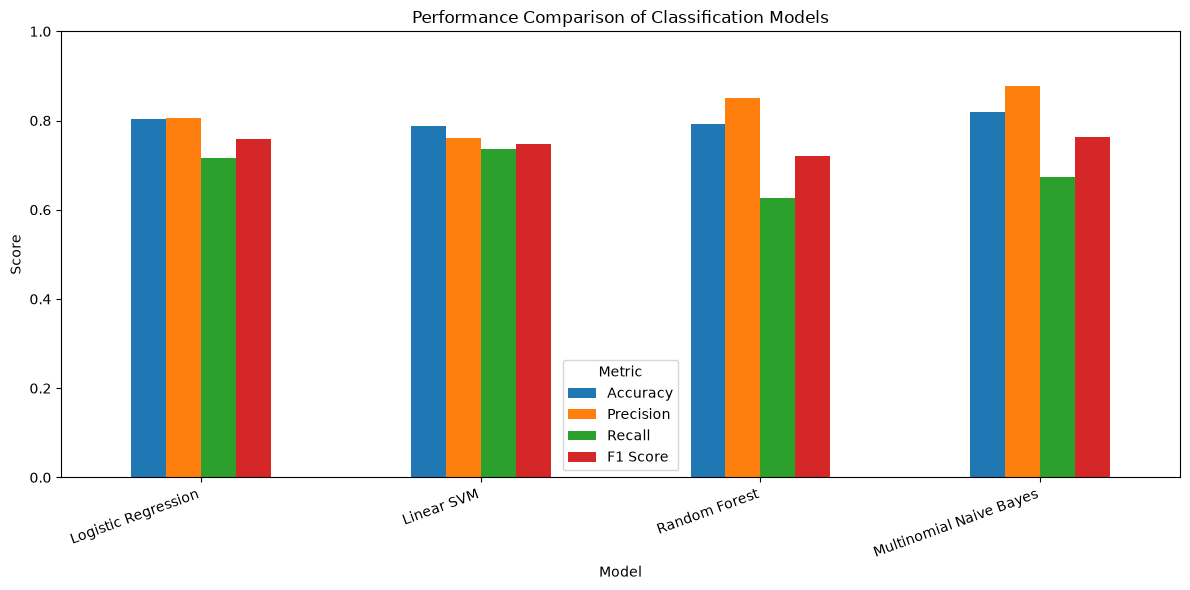

In [101]:
plot_df = results_df.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Performance Comparison of Classification Models"
)

plt.ylabel("Score")
plt.xlabel("Model")

plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(
    title="Metric"
)

plt.tight_layout()
plt.show()

### Insights – Performance Comparison of Classification Models
# - Multinomial Naive Bayes achieved the highest initial accuracy (82.01%) and precision (87.85%).
# - Logistic Regression provided a strong balance of metrics, achieving 80.37% accuracy and 75.79% F1-score.
# - Linear SVM achieved the highest recall (73.70%) among these initial models, showing better ability to identify actual disaster # tweets.
# - Random Forest had high precision (85.03%) but the lowest recall (62.54%), meaning it missed more actual disaster tweets.
# - Naive Bayes had the highest initial F1-score (76.30%), making it the strongest model at this initial evaluation stage.
# - These are initial model results; after cross-validation and hyperparameter tuning, Linear SVM became the final selected model based on the final holdout evaluation.

In [102]:
#reload the notebook
importlib.reload(
    src.evaluation
)

from src.evaluation import (
    get_classification_report
)

In [103]:
# Print reports for all four models
print("LOGISTIC REGRESSION")
print("-" * 50)

print(
    get_classification_report(
        trained_models[
            "Logistic Regression"
        ],
        X_test,
        y_test
    )
)

LOGISTIC REGRESSION
--------------------------------------------------
              precision    recall  f1-score   support

Non-Disaster       0.80      0.87      0.83       869
    Disaster       0.81      0.72      0.76       654

    accuracy                           0.80      1523
   macro avg       0.80      0.79      0.80      1523
weighted avg       0.80      0.80      0.80      1523



In [104]:
print("LINEAR SVM")
print("-" * 50)

print(
    get_classification_report(
        trained_models["Linear SVM"],
        X_test,
        y_test
    )
)

LINEAR SVM
--------------------------------------------------
              precision    recall  f1-score   support

Non-Disaster       0.81      0.83      0.82       869
    Disaster       0.76      0.74      0.75       654

    accuracy                           0.79      1523
   macro avg       0.78      0.78      0.78      1523
weighted avg       0.79      0.79      0.79      1523



In [105]:
print("RANDOM FOREST")
print("-" * 50)

print(
    get_classification_report(
        trained_models[
            "Random Forest"
        ],
        X_test,
        y_test
    )
)

RANDOM FOREST
--------------------------------------------------
              precision    recall  f1-score   support

Non-Disaster       0.76      0.92      0.83       869
    Disaster       0.85      0.63      0.72       654

    accuracy                           0.79      1523
   macro avg       0.81      0.77      0.78      1523
weighted avg       0.80      0.79      0.79      1523



In [106]:
print("MULTINOMIAL NAIVE BAYES")
print("-" * 50)

print(
    get_classification_report(
        naive_bayes_model,
        X_test_tfidf,
        y_test
    )
)

MULTINOMIAL NAIVE BAYES
--------------------------------------------------
              precision    recall  f1-score   support

Non-Disaster       0.79      0.93      0.86       869
    Disaster       0.88      0.67      0.76       654

    accuracy                           0.82      1523
   macro avg       0.83      0.80      0.81      1523
weighted avg       0.83      0.82      0.82      1523



In [107]:
# reload
importlib.reload(
    src.evaluation
)

from src.evaluation import (
    get_confusion_matrix
)

In [108]:
# All four Confusion matrix
# Logistic Regression
cm_lr = get_confusion_matrix(
    trained_models["Logistic Regression"],
    X_test,
    y_test
)

print("Logistic Regression:")
print(cm_lr)


# Linear SVM
cm_svm = get_confusion_matrix(
    trained_models["Linear SVM"],
    X_test,
    y_test
)

print("\nLinear SVM:")
print(cm_svm)


# Random Forest
cm_rf = get_confusion_matrix(
    trained_models["Random Forest"],
    X_test,
    y_test
)

print("\nRandom Forest:")
print(cm_rf)


# Multinomial Naive Bayes
cm_nb = get_confusion_matrix(
    naive_bayes_model,
    X_test_tfidf,
    y_test
)

print("\nMultinomial Naive Bayes:")
print(cm_nb)

Logistic Regression:
[[756 113]
 [186 468]]

Linear SVM:
[[717 152]
 [172 482]]

Random Forest:
[[797  72]
 [245 409]]

Multinomial Naive Bayes:
[[808  61]
 [213 441]]


In [109]:
# Reload
importlib.reload(
    src.evaluation
)

from src.evaluation import (
    plot_confusion_matrix
)

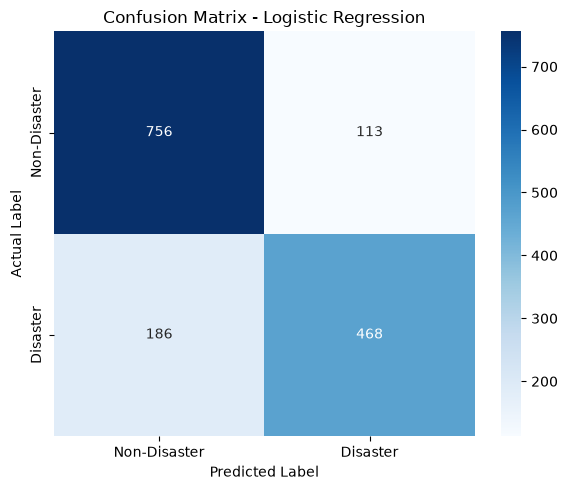

In [110]:
# Plot Logistic Regression:
plot_confusion_matrix(
    trained_models["Logistic Regression"],
    X_test,
    y_test,
    "Logistic Regression"
)

### Insights – Confusion Matrix: Logistic Regression
# - 756 True Negatives: Non-Disaster tweets were correctly classified as Non-Disaster.
# - 468 True Positives: Disaster tweets were correctly identified as Disaster.
# - 113 False Positives: Non-Disaster tweets were incorrectly predicted as Disaster.
# - 186 False Negatives: Disaster tweets were incorrectly predicted as Non-Disaster.
# - The model correctly classified 1,224 out of 1,523 tweets, giving an accuracy of approximately 80.37%.
# - The relatively higher number of False Negatives shows that Logistic Regression missed some actual disaster tweets, which explains its lower recall (71.56%).

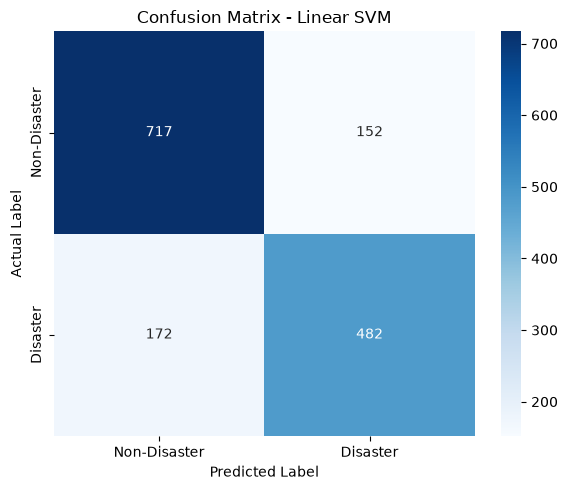

In [111]:
# Linear SVM:
plot_confusion_matrix(
    trained_models["Linear SVM"],
    X_test,
    y_test,
    "Linear SVM"
)

### Insights – Confusion Matrix: Linear SVM
# - 717 True Negatives: Non-Disaster tweets were correctly classified as Non-Disaster.
# - 482 True Positives: Disaster tweets were correctly identified as Disaster.
# - 152 False Positives: Non-Disaster tweets were incorrectly classified as Disaster.
# - 172 False Negatives: Actual Disaster tweets were incorrectly classified as Non-Disaster.
# - The model correctly classified 1,199 out of 1,523 tweets, giving an initial accuracy of approximately 78.73%.
# - Compared with Logistic Regression, Linear SVM identified more actual disaster tweets, resulting in a higher recall of 73.70%, #   but it also produced more false positives.
# - These results are for the initial Linear SVM; its performance improved later after hyperparameter tuning.

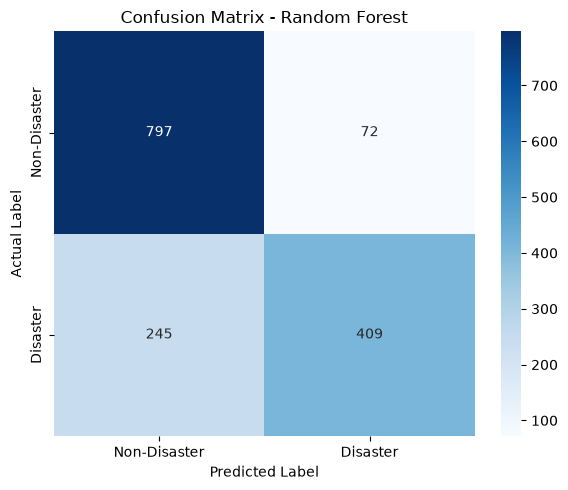

In [112]:
# Random Forest:
plot_confusion_matrix(
    trained_models["Random Forest"],
    X_test,
    y_test,
    "Random Forest"
)

### Insights – Confusion Matrix: Random Forest
# - 797 True Negatives: Non-Disaster tweets were correctly classified as Non-Disaster.
# - 409 True Positives: Disaster tweets were correctly identified as Disaster.
# - 72 False Positives: Non-Disaster tweets were incorrectly classified as Disaster.
# - 245 False Negatives: Actual Disaster tweets were incorrectly classified as Non-Disaster.
# - Random Forest achieved approximately 79.19% accuracy and a high precision of 85.03%.
# - However, it had the highest number of false negatives (245), resulting in a relatively low recall of 62.54%.
# - This indicates that Random Forest was conservative in predicting the Disaster class—its disaster predictions were often #correct, but it missed many actual disaster tweets.

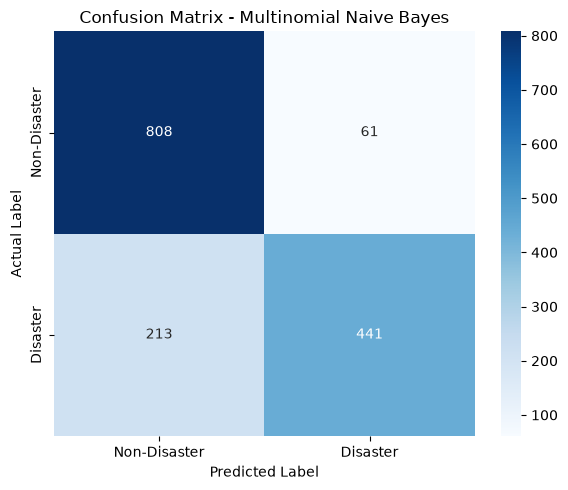

In [113]:
# Naive Bayes:
plot_confusion_matrix(
    naive_bayes_model,
    X_test_tfidf,
    y_test,
    "Multinomial Naive Bayes"
)

### Insights – Confusion Matrix: Multinomial Naive Bayes
# - 808 True Negatives: Non-Disaster tweets were correctly classified as Non-Disaster.
# - 441 True Positives: Disaster tweets were correctly identified as Disaster.
# - 61 False Positives: Non-Disaster tweets were incorrectly classified as Disaster.
# - 213 False Negatives: Actual Disaster tweets were incorrectly classified as Non-Disaster.
# - It achieved the highest initial accuracy (82.01%) and highest precision (87.85%) among the initial models.
# - The very low number of false positives (61) shows that when Naive Bayes predicted a Disaster tweet, it was usually correct.
# - However, its recall was 67.43%, showing that it still missed a considerable number of actual Disaster tweets.
# - Overall, Multinomial Naive Bayes was the strongest model in the initial evaluation, before cross-validation and hyperparameter tuning led to the final selection of tuned Linear SVM.

In [114]:
# ROC-AUC
import importlib
import src.evaluation

importlib.reload(
    src.evaluation
)

from src.evaluation import (
    calculate_roc_auc
)

print(
    "ROC-AUC functions imported successfully!"
)

ROC-AUC functions imported successfully!


In [115]:
# Calculate ROC-AUC for all four models
roc_auc_results = {
    "Logistic Regression": calculate_roc_auc(
        trained_models["Logistic Regression"],
        X_test,
        y_test
    ),

    "Linear SVM": calculate_roc_auc(
        trained_models["Linear SVM"],
        X_test,
        y_test
    ),

    "Random Forest": calculate_roc_auc(
        trained_models["Random Forest"],
        X_test,
        y_test
    ),

    "Multinomial Naive Bayes": calculate_roc_auc(
        naive_bayes_model,
        X_test_tfidf,
        y_test
    )
}

In [116]:
# Display
print("ROC-AUC RESULTS")
print("-" * 45)

for model_name, score in roc_auc_results.items():

    print(
        f"{model_name}: {score:.4f}"
    )

ROC-AUC RESULTS
---------------------------------------------
Logistic Regression: 0.8654
Linear SVM: 0.8583
Random Forest: 0.8586
Multinomial Naive Bayes: 0.8646


In [117]:
# Add ROC-AUC to your results table
results_df["ROC-AUC"] = (
    results_df["Model"]
    .map(roc_auc_results)
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.803677,0.805508,0.715596,0.757895,0.865361
1,Linear SVM,0.787262,0.760252,0.737003,0.748447,0.858307
2,Random Forest,0.791858,0.850312,0.625382,0.720705,0.858588
3,Multinomial Naive Bayes,0.820092,0.878486,0.674312,0.762976,0.864602


In [118]:
# For a cleaner percentage table:
results_display = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_display[
    metric_columns
] = (
    results_display[metric_columns] * 100
).round(2)

results_display

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,80.37,80.55,71.56,75.79,86.54
1,Linear SVM,78.73,76.03,73.70,74.84,85.83
2,Random Forest,79.19,85.03,62.54,72.07,85.86
3,Multinomial Naive Bayes,82.01,87.85,67.43,76.30,86.46


In [119]:
# Calculate AP for all four models
# Reload the module:
import importlib
import src.evaluation

importlib.reload(
    src.evaluation
)

from src.evaluation import (
    calculate_average_precision
)

In [120]:
ap_results = {
    "Logistic Regression": calculate_average_precision(
        trained_models["Logistic Regression"],
        X_test,
        y_test
    ),

    "Linear SVM": calculate_average_precision(
        trained_models["Linear SVM"],
        X_test,
        y_test
    ),

    "Random Forest": calculate_average_precision(
        trained_models["Random Forest"],
        X_test,
        y_test
    ),

    "Multinomial Naive Bayes": calculate_average_precision(
        naive_bayes_model,
        X_test_tfidf,
        y_test
    )
}

In [121]:
# Display:
print("AVERAGE PRECISION RESULTS")
print("-" * 45)

for model_name, score in ap_results.items():
    print(
        f"{model_name}: {score:.4f}"
    )

AVERAGE PRECISION RESULTS
---------------------------------------------
Logistic Regression: 0.8623
Linear SVM: 0.8546
Random Forest: 0.8511
Multinomial Naive Bayes: 0.8676


In [122]:
# Add AP to final comparison table
results_df["Average Precision"] = (
    results_df["Model"]
    .map(ap_results)
)

In [123]:
# percentage table:
results_display = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "Average Precision"
]

results_display[
    metric_columns
] = (
    results_display[metric_columns] * 100
).round(2)

results_display

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression,80.37,80.55,71.56,75.79,86.54,86.23
1,Linear SVM,78.73,76.03,73.70,74.84,85.83,85.46
2,Random Forest,79.19,85.03,62.54,72.07,85.86,85.11
3,Multinomial Naive Bayes,82.01,87.85,67.43,76.30,86.46,86.76


In [124]:
# save and reload 
importlib.reload(
    src.evaluation
)

from src.evaluation import (
    get_precision_recall_data
)

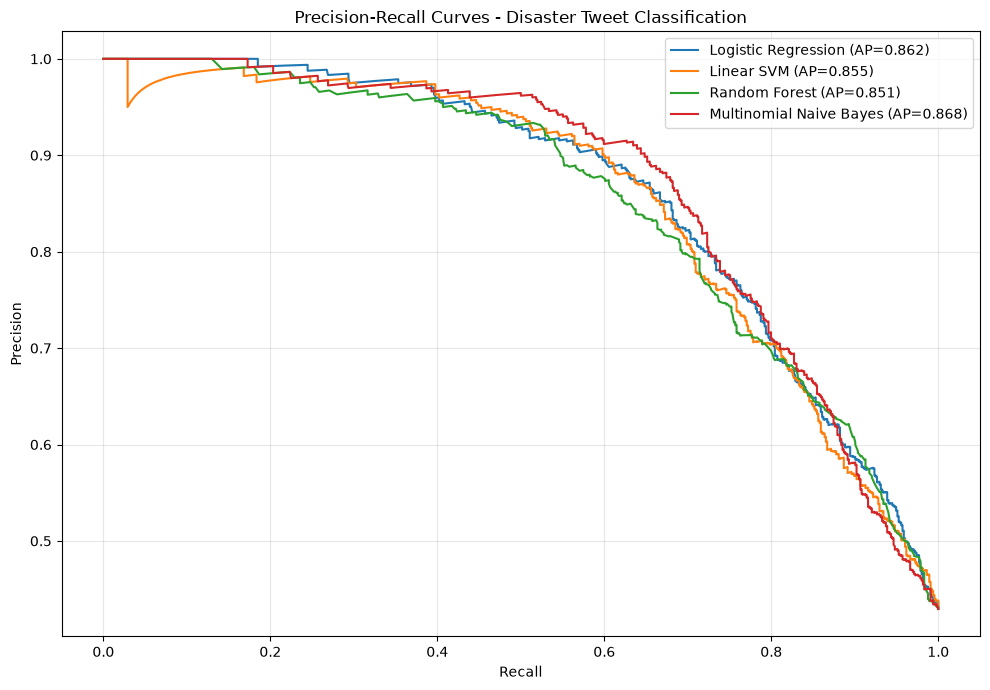

In [125]:
# Plot all four Precision–Recall curves
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

model_inputs = {
    "Logistic Regression": (
        trained_models["Logistic Regression"],
        X_test
    ),

    "Linear SVM": (
        trained_models["Linear SVM"],
        X_test
    ),

    "Random Forest": (
        trained_models["Random Forest"],
        X_test
    ),

    "Multinomial Naive Bayes": (
        naive_bayes_model,
        X_test_tfidf
    )
}


for name, (model, features) in model_inputs.items():

    precision, recall, ap_score = (
        get_precision_recall_data(
            model,
            features,
            y_test
        )
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap_score:.3f})"
    )


plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curves - Disaster Tweet Classification"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

### Insights – Precision-Recall Curves
# - Multinomial Naive Bayes achieved the highest Average Precision (AP = 0.868) among the initial models.
# - Logistic Regression followed closely with an AP of 0.862.
# - Linear SVM achieved an AP of 0.855, showing a strong balance between precision and recall.
# - Random Forest had the lowest AP at 0.851, although the difference between all four models is relatively small.
# - The curves show the expected precision–recall trade-off: as recall increases, precision generally decreases.
# - Overall, all four models show good discrimination, with AP scores above 0.85.
# - These curves represent the initial model evaluation; after validation and hyperparameter tuning, Linear SVM was selected as    the final model.

## Task 3.2: Model Validation

Stratified 5-fold cross-validation is performed to evaluate
the stability and generalization of the classification models.
TF-IDF is fitted independently within each fold to prevent
information leakage between training and validation data.

In [126]:
import importlib
import src.validation

importlib.reload(
    src.validation
)

from src.validation import (
    cross_validate_models
)

print(
    "Validation module imported successfully!"
)

Validation module imported successfully!


In [127]:
cv_results = cross_validate_models(
    train_df["processed_text"],
    train_df["target"],
    n_splits=5
)

cv_results

Cross-validating Logistic Regression...
Cross-validating Linear SVM...
Cross-validating Multinomial Naive Bayes...


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,F1 Std
0,Logistic Regression,0.799278,0.828154,0.672394,0.742156,0.858592,0.011464
1,Linear SVM,0.773655,0.751438,0.707176,0.728554,0.837321,0.011621
2,Multinomial Naive Bayes,0.796816,0.853230,0.636840,0.729232,0.855168,0.015688


In [128]:
# Display percentages:
cv_display = cv_results.copy()

cv_columns = [
    "CV Accuracy",
    "CV Precision",
    "CV Recall",
    "CV F1",
    "CV ROC-AUC",
    "F1 Std"
]

cv_display[
    cv_columns
] = (
    cv_display[cv_columns] * 100
).round(2)

cv_display

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,F1 Std
0,Logistic Regression,79.93,82.82,67.24,74.22,85.86,1.15
1,Linear SVM,77.37,75.14,70.72,72.86,83.73,1.16
2,Multinomial Naive Bayes,79.68,85.32,63.68,72.92,85.52,1.57


In [129]:
# Run tuning:
import importlib
import src.validation

importlib.reload(
    src.validation
)

from src.validation import (
    tune_logistic_regression
)

In [130]:
# lr_grid = tune_logistic_regression
(
train_df["processed_text"],
train_df["target"]
)

(0                                 christian attacked muslim temple mount waving israeli flag via pamela geller
 1                                                             girlfriend completely gorgeous woman crush stuff
 2                                                                                                       u dick
 3                      new isi video isi threatens behead croatian hostage within hour tlvfaces tlvfacesauspol
 4                                                       perspective terrorism understanding jihadi proto state
                                                          ...                                                  
 6083    ironic anniversary hiroshima current president helping terrorist nation acquire nuclear weapon traitor
 6084                                                                                      country chim survive
 6085                            drowning girl caitlin r kiernan centipede press signed numbered limited

In [131]:
print("train_df shape:", train_df.shape)

print(
    train_df[
        ["processed_text", "target"]
    ].head()
)

train_df shape: (6088, 15)
                                                                            processed_text  \
0             christian attacked muslim temple mount waving israeli flag via pamela geller   
1                                         girlfriend completely gorgeous woman crush stuff   
2                                                                                   u dick   
3  new isi video isi threatens behead croatian hostage within hour tlvfaces tlvfacesauspol   
4                                   perspective terrorism understanding jihadi proto state   

   target  
0       1  
1       0  
2       0  
3       1  
4       1  


In [132]:
lr_grid = tune_logistic_regression(
    train_df["processed_text"],
    train_df["target"]
)

print("Logistic Regression tuning completed!")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Logistic Regression tuning completed!


In [133]:
# Check the tuning result:
print(
    "Best Parameters:"
)

print(
    lr_grid.best_params_
)

print(
    "\nBest CV F1 Score:"
)

print(
    round(
        lr_grid.best_score_ * 100,
        2
    ),
    "%"
)

Best Parameters:
{'classifier__C': 0.5, 'classifier__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}

Best CV F1 Score:
75.29 %


In [134]:
# Check train-vs-validation performance
return_train_score=True

In [135]:
# inspect whether the tuned model is showing signs of overfitting.
# Check Overfitting
best_index = lr_grid.best_index_

best_train_f1 = (
    lr_grid.cv_results_[
        "mean_train_score"
    ][best_index]
)

best_validation_f1 = (
    lr_grid.cv_results_[
        "mean_test_score"
    ][best_index]
)

print(
    "Mean Training F1:",
    round(best_train_f1 * 100, 2),
    "%"
)

print(
    "Mean Validation F1:",
    round(best_validation_f1 * 100, 2),
    "%"
)

print(
    "Train-Validation Gap:",
    round(
        (
            best_train_f1 -
            best_validation_f1
        ) * 100,
        2
    ),
    "percentage points"
)

Mean Training F1: 85.22 %
Mean Validation F1: 75.29 %
Train-Validation Gap: 9.93 percentage points


# Tune Naive Bayes

In [136]:
# Reload
import importlib
import src.validation

importlib.reload(src.validation)

from src.validation import tune_naive_bayes

In [137]:
nb_grid = tune_naive_bayes(
    train_df["processed_text"],
    train_df["target"]
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


In [138]:
# 
print("Best Parameters:")
print(nb_grid.best_params_)

print("\nBest CV F1 Score:")
print(
    round(
        nb_grid.best_score_ * 100,
        2
    ),
    "%"
)

Best Parameters:
{'classifier__alpha': 1.0, 'classifier__fit_prior': False, 'tfidf__ngram_range': (1, 1)}

Best CV F1 Score:
75.11 %


In [139]:
# checking train-validation gap:
best_index_nb = nb_grid.best_index_

nb_train_f1 = (
    nb_grid.cv_results_[
        "mean_train_score"
    ][best_index_nb]
)

nb_validation_f1 = (
    nb_grid.cv_results_[
        "mean_test_score"
    ][best_index_nb]
)

nb_gap = (
    nb_train_f1 -
    nb_validation_f1
)

print(
    "Mean Training F1:",
    round(nb_train_f1 * 100, 2),
    "%"
)

print(
    "Mean Validation F1:",
    round(nb_validation_f1 * 100, 2),
    "%"
)

print(
    "Train-Validation Gap:",
    round(nb_gap * 100, 2),
    "percentage points"
)

Mean Training F1: 85.19 %
Mean Validation F1: 75.11 %
Train-Validation Gap: 10.08 percentage points


# Tune Linear SVM

In [140]:
# reload:
import importlib
import src.validation

importlib.reload(src.validation)

from src.validation import tune_linear_svm

In [141]:
svm_grid = tune_linear_svm(
    train_df["processed_text"],
    train_df["target"]
)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


In [142]:
print("Best Parameters:")
print(svm_grid.best_params_)

print("\nBest CV F1 Score:")
print(
    round(
        svm_grid.best_score_ * 100,
        2
    ),
    "%"
)

Best Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}

Best CV F1 Score:
75.29 %


In [143]:
# calculating the train-validation gap:
best_index_svm = svm_grid.best_index_

svm_train_f1 = (
    svm_grid.cv_results_[
        "mean_train_score"
    ][best_index_svm]
)

svm_validation_f1 = (
    svm_grid.cv_results_[
        "mean_test_score"
    ][best_index_svm]
)

svm_gap = (
    svm_train_f1 -
    svm_validation_f1
)

print(
    "Mean Training F1:",
    round(svm_train_f1 * 100, 2),
    "%"
)

print(
    "Mean Validation F1:",
    round(svm_validation_f1 * 100, 2),
    "%"
)

print(
    "Train-Validation Gap:",
    round(svm_gap * 100, 2),
    "percentage points"
)

Mean Training F1: 87.03 %
Mean Validation F1: 75.29 %
Train-Validation Gap: 11.74 percentage points


In [144]:
# reload:
import importlib
import src.validation

importlib.reload(src.validation)

from src.validation import create_tuning_comparison

In [145]:
tuning_comparison = create_tuning_comparison(
    lr_grid,
    nb_grid,
    svm_grid
)

tuning_comparison

,Model,Training F1,Validation F1,Validation F1 Std,Train-Validation Gap
0,Logistic Regression,0.852244,0.752939,0.016355,0.099305
1,Multinomial Naive Bayes,0.851915,0.751128,0.017568,0.100787
2,Linear SVM,0.870330,0.752938,0.016334,0.117393


In [146]:
# cleaner percentage table:
tuning_display = tuning_comparison.copy()

percentage_columns = [
    "Training F1",
    "Validation F1",
    "Validation F1 Std",
    "Train-Validation Gap"
]

tuning_display[
    percentage_columns
] = (
    tuning_display[
        percentage_columns
    ] * 100
).round(2)

tuning_display

,Model,Training F1,Validation F1,Validation F1 Std,Train-Validation Gap
0,Logistic Regression,85.22,75.29,1.64,9.93
1,Multinomial Naive Bayes,85.19,75.11,1.76,10.08
2,Linear SVM,87.03,75.29,1.63,11.74


In [147]:
# save the validation results
output_path = (
    PROJECT_ROOT
    / "reports"
    / "tuned_model_validation.csv"
)

tuning_display.to_csv(
    output_path,
    index=False
)

print(
    "Validation results saved to:",
    output_path
)

Validation results saved to: c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\reports\tuned_model_validation.csv


In [148]:
# Reload in notebook
import importlib
import src.validation

importlib.reload(src.validation)

from src.validation import evaluate_tuned_models

In [149]:
# final evaluation:
final_results = evaluate_tuned_models(
    lr_grid,
    nb_grid,
    svm_grid,
    test_df["processed_text"],
    test_df["target"]
)

final_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Logistic Regression,0.808930,0.780526,0.772171,0.776326,0.869835
1,Tuned Multinomial Naive Bayes,0.795141,0.772293,0.741590,0.756630,0.864129
2,Tuned Linear SVM,0.810900,0.783282,0.773700,0.778462,0.870912


In [150]:
# Convert to percentage 
final_display = final_results.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

final_display[
    metric_columns
] = (
    final_display[
        metric_columns
    ] * 100
).round(2)

final_display

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Logistic Regression,80.89,78.05,77.22,77.63,86.98
1,Tuned Multinomial Naive Bayes,79.51,77.23,74.16,75.66,86.41
2,Tuned Linear SVM,81.09,78.33,77.37,77.85,87.09


In [151]:
# Save the final evaluation
output_path = (
    PROJECT_ROOT
    / "reports"
    / "final_tuned_model_results.csv"
)

final_display.to_csv(
    output_path,
    index=False
)

print(
    "Final results saved to:",
    output_path
)

Final results saved to: c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\reports\final_tuned_model_results.csv


In [153]:
# Error Analysis:
import importlib
import src.validation

importlib.reload(src.validation)

from src.validation import create_error_analysis

In [154]:
# Get the final SVM:
final_model = svm_grid.best_estimator_

In [155]:
false_positives, false_negatives = (
    create_error_analysis(
        final_model,
        test_df
    )
)

print(
    "False Positives:",
    len(false_positives)
)

print(
    "False Negatives:",
    len(false_negatives)
)

print(
    "Total Errors:",
    len(false_positives)
    + len(false_negatives)
)

False Positives: 140
False Negatives: 148
Total Errors: 288


In [156]:
# Inspect the mistakes
# First, false positives:
false_positives[
    [
        "text",
        "target",
        "predicted_target"
    ]
].head(10)

,text,target,predicted_target
23,Cascada - Evacuate The Dancefloor (Official Video) https://t.co/OHCx3y8l4s via @YouTube,0,1
24,@AGeekyFangirl14 's things she looks in a significant other:\n1. Beautiful eyes.\n2. Humor.\n3. Farts that creates an earthquake.\n\n????????,0,1
34,How many cars do those cyclists wreck going past scratching with pedals. They should be banned #c4news,0,1
39,she's a suicide bomb,0,1
44,@TroySlaby22 slicker than an oil spill,0,1
57,namjoon's FANTASTIC IS BOMB BYE OMG,0,1
59,@TheEconomist Step one: get that mass murderer's portrait off the yuan.,0,1
60,@YoungHeroesID Lava Blast &amp; Power Red #PantherAttack @JamilAzzaini @alifaditha,0,1
86,.POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4,0,1
100,Ignition Knock (Detonation) Sensor-Senso Standard KS57 http://t.co/bzZdeDcthL http://t.co/OQJNUyIBxM,0,1


In [157]:
# false negatives:
false_negatives[
    [
        "text",
        "target",
        "predicted_target"
    ]
].head(10)

,text,target,predicted_target
0,Towboat trek sympathy deluge falls: VTc http://t.co/eaaQUMkkc9,1,0
1,@PhilipDuncan @breakfastone People 'annihilated by last nights weather'... Really Philip thought you would have forecast that...,1,0
4,@TradCatKnight (1) Russia may have played into reason but that link is BS. Okanowa was bloody and mainline invasion looked like a bloody,1,0
25,Jacksonville Busines FedEx stops shipping potential bioterror pathogens http://t.co/sHzsYmaUSi,1,0
26,OSP concerned about mounting fatalities http://t.co/YmP0gInwza http://t.co/FYIOQvIOif,1,0
42,RT grant_factory: #grants #funds Weymouth meeting on seawalls and flood grants set for Thursday night _x0089_Û_ http://t.co/Th2WLilBmo,1,0
53,Pandemonium In Aba As Woman Delivers Baby Without Face (Photos) - http://t.co/c5u9qshhnb,1,0
55,I can't believe Blevins got injured falling off a curb. That's something that would happen to me never it expected for a pro player,1,0
56,I was over here dreaming peacefully then that loud ass thunder wanted to scare me. ??,1,0
88,@UnrealTouch fuck sake john Jesus my heart just sunk.,1,0


In [158]:
# calculate the confusion matrix:
from sklearn.metrics import confusion_matrix

y_pred_final = final_model.predict(
    test_df["processed_text"]
)

cm_final = confusion_matrix(
    test_df["target"],
    y_pred_final
)

print(
    "Final Linear SVM Confusion Matrix:"
)

print(cm_final)

Final Linear SVM Confusion Matrix:
[[729 140]
 [148 506]]


In [159]:
# Qualitative Error Analysis:
error_columns = [
    "text",
    "processed_text",
    "target",
    "predicted_target"
]

print("FALSE POSITIVE EXAMPLES")
display(
    false_positives[
        error_columns
    ].head(10)
)

print("\nFALSE NEGATIVE EXAMPLES")
display(
    false_negatives[
        error_columns
    ].head(10)
)

FALSE POSITIVE EXAMPLES


,text,processed_text,target,predicted_target
23,Cascada - Evacuate The Dancefloor (Official Video) https://t.co/OHCx3y8l4s via @YouTube,cascada evacuate dancefloor official video via,0,1
24,@AGeekyFangirl14 's things she looks in a significant other:\n1. Beautiful eyes.\n2. Humor.\n3. Farts that creates an earthquake.\n\n????????,thing look significant beautiful eye humor fart creates earthquake,0,1
34,How many cars do those cyclists wreck going past scratching with pedals. They should be banned #c4news,many car cyclist wreck going past scratching pedal banned c news,0,1
39,she's a suicide bomb,suicide bomb,0,1
44,@TroySlaby22 slicker than an oil spill,slicker oil spill,0,1
57,namjoon's FANTASTIC IS BOMB BYE OMG,namjoon fantastic bomb bye omg,0,1
59,@TheEconomist Step one: get that mass murderer's portrait off the yuan.,step one get mass murderer portrait yuan,0,1
60,@YoungHeroesID Lava Blast &amp; Power Red #PantherAttack @JamilAzzaini @alifaditha,lava blast power red pantherattack,0,1
86,.POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4,potus strategicpatience strategy genocide refugee idp internally displaced people horror etc,0,1
100,Ignition Knock (Detonation) Sensor-Senso Standard KS57 http://t.co/bzZdeDcthL http://t.co/OQJNUyIBxM,ignition knock detonation sensor senso standard k,0,1



FALSE NEGATIVE EXAMPLES


,text,processed_text,target,predicted_target
0,Towboat trek sympathy deluge falls: VTc http://t.co/eaaQUMkkc9,towboat trek sympathy deluge fall vtc,1,0
1,@PhilipDuncan @breakfastone People 'annihilated by last nights weather'... Really Philip thought you would have forecast that...,people annihilated last night weather really philip thought would forecast,1,0
4,@TradCatKnight (1) Russia may have played into reason but that link is BS. Okanowa was bloody and mainline invasion looked like a bloody,russia may played reason link b okanowa bloody mainline invasion looked like bloody,1,0
25,Jacksonville Busines FedEx stops shipping potential bioterror pathogens http://t.co/sHzsYmaUSi,jacksonville busines fedex stop shipping potential bioterror pathogen,1,0
26,OSP concerned about mounting fatalities http://t.co/YmP0gInwza http://t.co/FYIOQvIOif,osp concerned mounting fatality,1,0
42,RT grant_factory: #grants #funds Weymouth meeting on seawalls and flood grants set for Thursday night _x0089_Û_ http://t.co/Th2WLilBmo,rt grant factory grant fund weymouth meeting seawall flood grant set thursday night x,1,0
53,Pandemonium In Aba As Woman Delivers Baby Without Face (Photos) - http://t.co/c5u9qshhnb,pandemonium aba woman delivers baby without face photo,1,0
55,I can't believe Blevins got injured falling off a curb. That's something that would happen to me never it expected for a pro player,believe blevins got injured falling curb something would happen never expected pro player,1,0
56,I was over here dreaming peacefully then that loud ass thunder wanted to scare me. ??,dreaming peacefully loud as thunder wanted scare,1,0
88,@UnrealTouch fuck sake john Jesus my heart just sunk.,fuck sake john jesus heart sunk,1,0


In [160]:
# save all errors for the report:
fp_path = (
    PROJECT_ROOT
    / "reports"
    / "false_positives.csv"
)

fn_path = (
    PROJECT_ROOT
    / "reports"
    / "false_negatives.csv"
)

false_positives.to_csv(
    fp_path,
    index=False
)

false_negatives.to_csv(
    fn_path,
    index=False
)

print("Saved:", fp_path)
print("Saved:", fn_path)

Saved: c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\reports\false_positives.csv
Saved: c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\reports\false_negatives.csv


### Error Analysis Insights

#  The final Linear SVM produced 140 False Positives and 148 False Negatives on the holdout test set.
# False Positives: Disaster-related words such as bomb, earthquake, wreck, spill, and detonation were sometimes used in         figurative, entertainment, technical, or unrelated contexts.
# False Negatives: Some actual disaster tweets contained unusual wording, abbreviations, noisy text, limited context, or indirect descriptions.
# The model can recognize statistical word and phrase patterns effectively but has limited understanding of the actual context and meaning of a sentence.
# TF-IDF + Linear SVM may struggle with sarcasm, metaphors, ambiguity, and complex language.
#  These errors suggest that future improvements could use context-aware NLP models to better understand the meaning behind tweets.

### Qualitative Error Analysis

To understand the limitations of the final Linear SVM model,
false-positive and false-negative predictions were examined.
This helps identify common language patterns that cause
misclassification.

In [162]:
# Part 4 — Task 4.1: Model Deployment
from src.model_persistence import save_model

final_model = svm_grid.best_estimator_

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "disaster_tweet_svm_pipeline.pkl"
)

save_model(
    final_model,
    MODEL_PATH
)

print("Final model saved successfully!")
print("Model path:", MODEL_PATH)

Final model saved successfully!
Model path: c:\Users\AMOGH\Desktop\Nexthikes_Projects\Project_7_DisasterTweetClassification\Disaster_Tweet_Classification\models\disaster_tweet_svm_pipeline.pkl


In [163]:
# Verify model loading:
from src.model_persistence import load_model

loaded_model = load_model(
    MODEL_PATH
)

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [164]:
print(loaded_model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, max_features=10000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LinearSVC(C=0.1, class_weight='balanced', random_state=42))])


In [165]:
# Test prediction.py:
import importlib
import src.prediction

importlib.reload(
    src.prediction
)

from src.prediction import predict_tweet

In [166]:
sample_tweets = [
    "A major earthquake has damaged several buildings",

    "Had an amazing day at the beach with my friends",

    "Emergency crews are responding to severe flooding"
]

for tweet in sample_tweets:

    result = predict_tweet(
        loaded_model,
        tweet
    )

    print("Tweet:")
    print(result["original_text"])

    print(
        "Processed:",
        result["processed_text"]
    )

    print(
        "Prediction:",
        result["label"]
    )

    print("-" * 60)

Tweet:
A major earthquake has damaged several buildings
Processed: major earthquake damaged several building
Prediction: Disaster
------------------------------------------------------------
Tweet:
Had an amazing day at the beach with my friends
Processed: amazing day beach friend
Prediction: Non-Disaster
------------------------------------------------------------
Tweet:
Emergency crews are responding to severe flooding
Processed: emergency crew responding severe flooding
Prediction: Disaster
------------------------------------------------------------


In [167]:
# Test empty-input handling:
try:

    predict_tweet(
        loaded_model,
        ""
    )

except ValueError as error:

    print(
        "Input validation works:",
        error
    )

Input validation works: Tweet cannot be empty.


### Final Project Insights
#   - The project demonstrates a complete end-to-end NLP and Machine Learning workflow for classifying Disaster and Non-Disaster tweets.
#   - The dataset contained 7,613 tweets, with a moderate class imbalance between the two classes.
#   - The workflow included data exploration, text preprocessing, feature engineering, model training, evaluation, cross-validation, hyperparameter tuning, and error analysis.
#   - After model comparison and tuning, Tuned Linear SVM was selected as the final model.
#   - The final model achieved 81.09% Accuracy, 78.33% Precision, 77.37% Recall, 77.85% F1-score, and 87.09% ROC-AUC on the holdout test set.
#   - Error analysis showed that context is a major challenge. Metaphorical or humorous disaster-related words can cause False Positives, while indirect or unusual language can cause False Negatives.
#   - TF-IDF + Linear SVM provides a strong and computationally efficient solution but has limited ability to understand sarcasm, ambiguity, metaphors, and deeper semantic meaning.
#   - Future improvements could explore context-aware NLP models such as Transformers for better understanding of complex language.
#   - The project follows a modular architecture, with reusable Python modules for preprocessing, feature engineering, training, evaluation, validation, model persistence, and prediction.
#   - The final model was successfully deployed through a dynamic Streamlit dashboard, enabling real-time classification of new tweets.
#   - Overall, the project demonstrates the complete journey from raw tweet data → trained ML model → validated results → real-time deployable application.